# Example data

HelioBeamAI is trained on data of the Jülich solar tower that are not published. `examples/data/`
contains both training dataset types for five heliostats (images stored as float16), so that the
formats can be inspected and the training code run. Full descriptions: `docs/data.md`.

| file | content | used for |
|---|---|---|
| `calibration_2026.pt` | measured flux images + conditions, 5 heliostats x 45 | transformer `T2026` |
| `projection_receiver.pt`, `projection_calibration.pt` | ray-traced flux on 6 parallel planes | projection CNN |
| `heliostat_positions.csv` | positions of the 5 heliostats (tower-base frame) | |

Heliostats: AC26 (near, west), AA44 (near, east), AO50 (middle, east), AY27 (far, west), BC71 (far,
east).

In [1]:
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from heliobeamai import normalize_heliostat_id

DATA = Path("data")
def load(name):
    d = torch.load(DATA / name, weights_only=False)
    for k, v in d.items():
        print(f"  {k:20s}", tuple(v.shape) if torch.is_tensor(v) else (v if not isinstance(v, list) else f"list[{len(v)}]"))
    return d

## Calibration datasets (transformer)

Each heliostat has `S` measurements: `imgs [H, S, 64, 64]` flux images (frame C, 6 m x 6 m around the
spot centroid, mean 0.1), `data [H, S, 7]` sun vector (3), aim direction (3, heliostat -> target),
aim distance in m, `ids` calibration record ids. In the 2026 dataset the 45 samples are 3 blocks of 15,
one per target group (`target_groups`: MFT, Lower, Upper); the first 5 of each block are the test
samples of the `T2026` split.

  imgs                 (5, 45, 64, 64)
  data                 (5, 45, 7)
  ids                  (5, 45)
  heliostat_ids        (5,)
  target_ids           (10,)
  samples_per_target   15
  target_groups        list[3]
  min_total_samples    10
  source               fluxTransData2026.pt


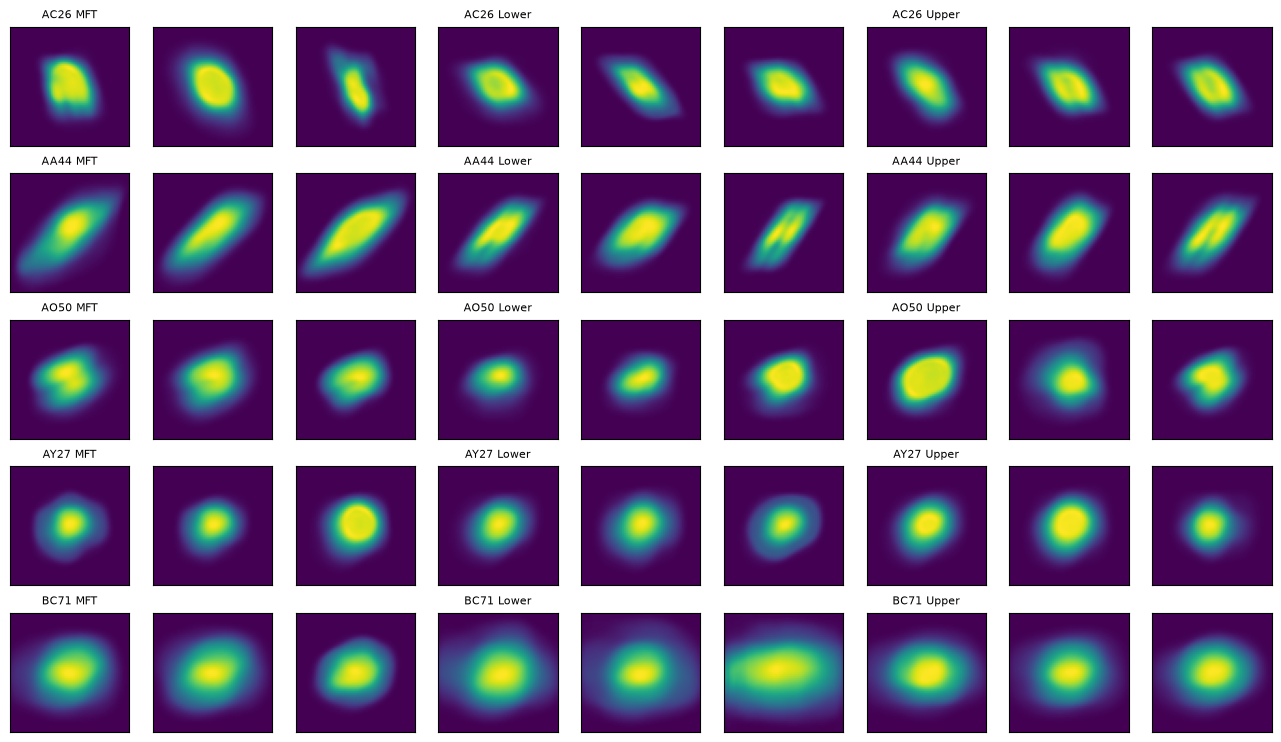

In [2]:
cal = load("calibration_2026.pt")
ids = [normalize_heliostat_id(int(h)) for h in cal["heliostat_ids"]]
fig, ax = plt.subplots(len(ids), 9, figsize=(13, 7.5))
for i, h in enumerate(ids):
    for j, k in enumerate([5, 8, 11, 20, 23, 26, 35, 38, 41]):
        ax[i, j].imshow(cal["imgs"][i, k].float()); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        if j % 3 == 0:
            ax[i, j].set_title(f"{h} {cal['target_groups'][j // 3]}", fontsize=8)
plt.tight_layout()

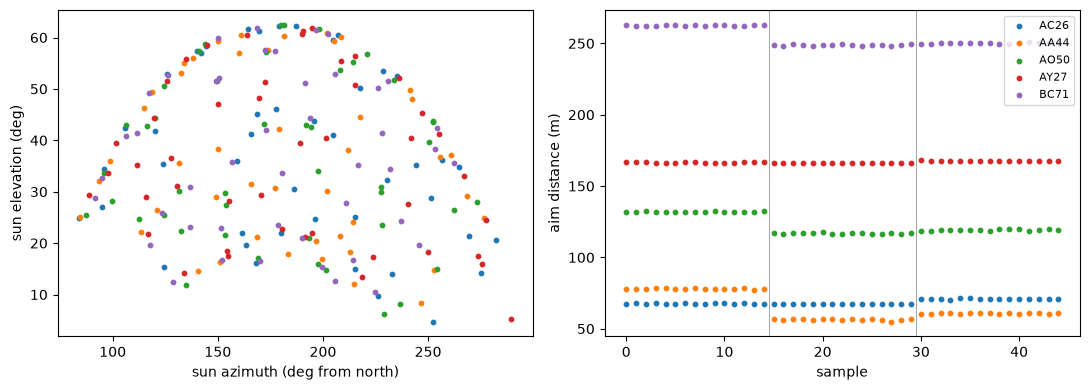

In [3]:
import math
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, h in enumerate(ids):
    s = cal["data"][i, :, :3].float()
    az = torch.rad2deg(torch.atan2(s[:, 0], s[:, 1])) % 360
    el = torch.rad2deg(torch.asin(s[:, 2]))
    ax[0].scatter(az, el, s=10, label=h)
    ax[1].scatter(torch.arange(45), cal["data"][i, :, 6], s=10, label=h)
ax[0].set_xlabel("sun azimuth (deg from north)"); ax[0].set_ylabel("sun elevation (deg)")
ax[1].set_xlabel("sample"); ax[1].set_ylabel("aim distance (m)"); ax[1].legend(fontsize=8)
for b in (15, 30):
    ax[1].axvline(b - 0.5, color="grey", lw=0.5)
plt.tight_layout()

## Projection data (projection CNN)

Ray-traced flux of one heliostat on 6 parallel planes (`fluxes [N, 6, 64, 64]`, frame C): plane 0 is
the aim plane, plane k lies k m further along the aim direction (`plane_centers`). The CNN learns the
ray directions that carry the spot from plane 0 to the others. `receiver` cases aim at the receiver
(0, 1, 54) m +- 2 m, `calibration` cases at the aim point of a real calibration record. Sun vectors
come from real calibration records of the heliostat.

projection_receiver.pt:
  format               heliobeamai.projection_data/1
  frame                C
  side_lengths_m       (6.0, 6.0)
  plane_spacing_m      1.0
  mode                 receiver
  generator            {'script': 'Raytracer/createProjectionDatasetV3.py', 'raytracer_fix': 'geometry.py getFacetPlane 2026-11-04', 'args': {'mode': 'receiver', 'suns_per_heliostat': 20, 'max_heliostats': 0, 'receiver_center': (0.0, 1.0, 54.0), 'aim_noise': 2.0, 'n_planes': 6, 'plane_spacing': 1.0, 'side': 6.0, 'resolution': 64, 'chunk_size': 100, 'seed': 0}}
  fluxes               (20, 6, 64, 64)
  plane_centers        (20, 6, 3)
  heliostat_positions  (20, 3)
  sun_vectors          (20, 3)
  heliostat_names      list[20]
  record_ids           list[20]


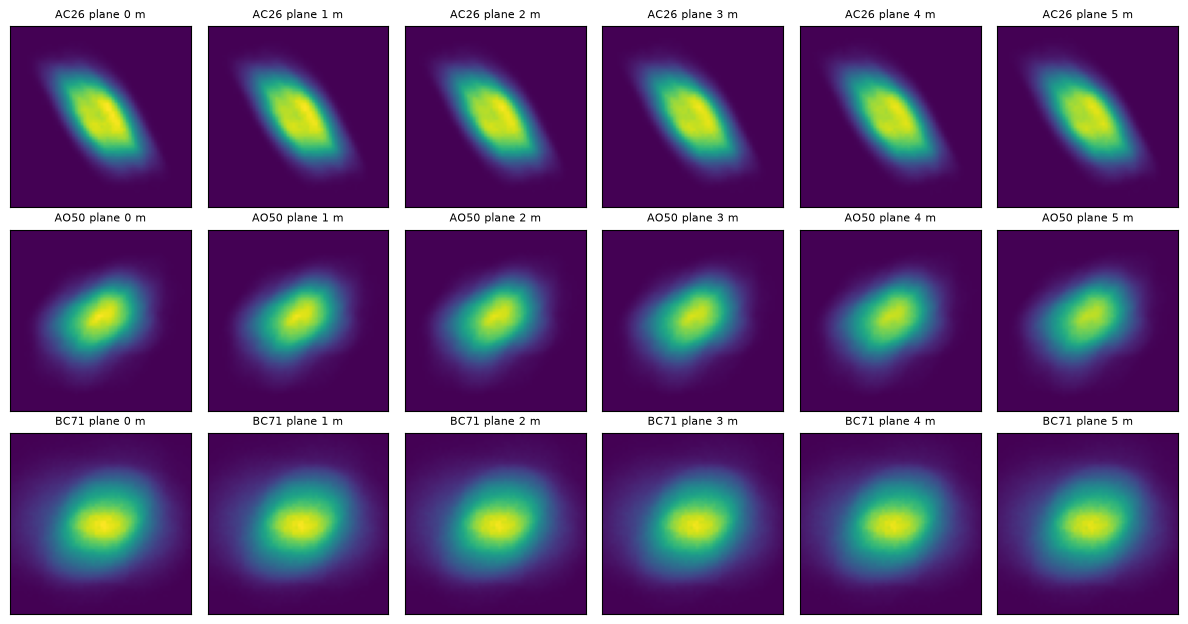

In [4]:
print("projection_receiver.pt:"); pr = load("projection_receiver.pt")
fig, ax = plt.subplots(3, 6, figsize=(12, 6.3))
for r, n in enumerate([0, 8, 16]):
    vmax = float(pr["fluxes"][n].float().max())
    for k in range(6):
        ax[r, k].imshow(pr["fluxes"][n, k].float(), vmin=0, vmax=vmax)
        ax[r, k].set_title(f"{pr['heliostat_names'][n]} plane {k} m", fontsize=8)
        ax[r, k].set_xticks([]); ax[r, k].set_yticks([])
plt.tight_layout()

Training on these files:

```bash
heliobeamai train-transformer configs/transformer/example.yaml          # transformer, CPU, minutes
heliobeamai train-projector --data examples/data/projection_receiver.pt --output runs/projector/example.pt
```